# Lecture 12 notebook: the tape

This notebook replays Lecture 12 for any USD-M perpetual on Binance and any period: it downloads the aggregated trades, checks them,
finds and patches holes, builds the derived tables, and then explores and describes the data. Everything runs on an ordinary computer:
the pipeline works one month, and within a month one day, at a time.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings: market, period, data folder; what to expect in time and memory | Appendix A.2 |
| 1 | The pipeline: download and check, find holes, patch, clean, aggregate, sequence | §4, §5 |
| 2 | Explorer: coverage map, list of events, day view, density of a month, raw rows | §5 |

The pipeline code is in `tape.py`, next to this notebook. Data are written to `data/` at the top of the repository, which git ignores:
nothing downloaded is ever committed. To keep data elsewhere, set the environment variable `TAPE_ROOT` before starting Jupyter.

## 0. Settings

Choose the market and the period (months, `YYYY-MM`). The default, August and September 2022, contains the archive's holes of §5.2:
four missing days in August and September, a day missing on 10 September, two duplicated days, and the six minutes missing from the archive on 6 September.

In [1]:
import os, sys, time
os.environ.setdefault("POLARS_MAX_THREADS", "4")      # fewer threads: lower peak memory, longer run
import polars as pl, psutil
import tape

SYMBOL = "BTCUSDT"     # any USD-M perpetual, e.g. "ETHUSDT"
START = "2022-08"      # first month
END = "2022-09"        # last month

pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(60)
print("data folder:", tape.ROOT)
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB; "
      f"each stage waits until {tape.MIN_FREE_GB} GB are free")

data folder: …/systematic-trading-notes/data
free memory: 2.3 GB of 16.9 GB; each stage waits until 2.5 GB are free


**What to expect.** Measured on a computer with 16 GB of memory and four threads (Appendix A.2), per month:

| Stage | Peak memory | Time per month |
|---|---|---|
| Get: download, convert, check | about 2.3 GB | 1–2 minutes, mostly downloading |
| Find holes, patch, clean | about 3.2 GB | a few minutes for the whole period |
| Aggregate | 1.9–3.1 GB | 5 to 15 seconds |
| Sequence | 1.6–3.2 GB | 30 seconds to 2 minutes; longer in busy months |

A month of BTCUSDT takes about 0.4 GB of disk as Parquet. Months already downloaded are not downloaded again,
so the cell below can be rerun after an interruption.

## 1. The pipeline

`tape.run_pipeline` runs the six stages of §4.3, each stage and month in a fresh process, so that its memory is freed and its peak measured:

1. **get**: download the monthly zip, verify its checksum, convert to Parquet, check rows, IDs and time order, log, delete the zip;
2. **find holes**: every jump and every repeat in the trade IDs, across month boundaries;
3. **patch**: for each missing range, download the daily files of the days it spans, and check that they fill it exactly;
4. **clean**: for months with holes or repeats only, write raw + patches − duplicates;
5. **aggregate**: counts, volumes, histograms and quantiles, with Polars' streaming engine;
6. **sequence**: day by day, with the last trades of each day carried into the next: bars, realised variance, durations, persistence, flags.

In [2]:
t0 = time.time()
holes, patches, log = tape.run_pipeline(SYMBOL, START, END)
print(f"done in {(time.time() - t0) / 60:.1f} minutes")

get 2022-08: done


get 2022-09: done


holes: 5 ranges of missing IDs, 2 days with repeated IDs


aggregate and sequence 2022-08: done


aggregate and sequence 2022-09: done


done in 10.9 minutes


**Data quality report.** How complete and how clean the period is, before any detail. Shares are of all trades in the period;
nothing is deleted, so every figure describes what the analyses use. The default period is the worst of the five years, chosen to show
the repairs; over the five years from October 2021, 99.9988% of the trades Binance recorded are in the data.

In [3]:
def quality_report(symbol, start, end, holes, patches):
    D_ = tape.ROOT / "interim" / "tape" / symbol; ms_ = tape.months(start, end)
    days_ = pl.concat([pl.read_parquet(D_ / ym / "days.parquet") for ym in ms_])
    fl = pl.concat([pl.read_parquet(D_ / ym / "flag_counts.parquet") for ym in ms_])
    ex_ = pl.concat([pl.read_parquet(D_ / ym / "flag_examples.parquet") for ym in ms_ if pl.read_parquet(D_ / ym / "flag_examples.parquet").height])
    n = int(days_["trades"].sum()); f = lambda rule: int(fl.filter(pl.col("rule") == rule)["n"].sum())
    miss = int(holes.filter(pl.col("kind") == "missing")["n"].sum()); rep = int(holes.filter(pl.col("kind") == "repeated")["n"].sum())
    filled = int(patches.filter(pl.col("status") == "filled")["n"].sum()) if patches.height else 0
    unfilled = miss - filled; total = n + unfilled                                   # what Binance recorded: the trades we have, plus those missing everywhere
    bad_days = set()
    for h in (patches.filter(pl.col("status") != "filled").iter_rows(named=True) if patches.height else []):
        bad_days.update(tape.hole_days(h["from_ms"], h["to_ms"], 1))
    silent_s = float(ex_.filter(pl.col("rule") == "silence over 60 seconds")["value"].sum()) if ex_.height else 0.0
    unusual = f("spike and revert") + f("jump that persists")
    pct = lambda x, base: f"{100 * x / base:.4f}%"
    rows = [("Trades in the period, after patching", f"{n:,}", "100%"),
            ("Missing from the monthly files", f"{miss:,}", pct(miss, total)),
            ("  filled exactly from the daily files", f"{filled:,}", pct(filled, total)),
            ("  missing from the whole archive, recorded", f"{unfilled:,}", pct(unfilled, total)),
            ("Duplicated rows, kept once", f"{rep:,}", pct(rep, n)),
            ("Days complete", f"{days_.height - len(bad_days)} of {days_.height}", f"{100 * (days_.height - len(bad_days)) / days_.height:.1f}%"),
            ("Time with no trade for over a minute", f"{silent_s / 60:,.1f} minutes", f"{100 * silent_s / (days_.height * 86_400):.4f}% of the time"),
            ("Unusual prints, flagged and kept", f"{unusual:,}", pct(unusual, n)),
            ("Prices off the tick grid, kept", f"{int(days_['off_grid'].sum()):,}", pct(int(days_["off_grid"].sum()), n)),
            ("Quantities off the lot size", f"{int(days_['off_lot'].sum()):,}", pct(int(days_["off_lot"].sum()), n))]
    print(f"{symbol}, {start} to {end}: {100 * n / total:.4f}% of the trades Binance recorded are in the data; nothing was deleted.")
    return pl.DataFrame(rows, schema=["measure", "count", "share"], orient="row")

quality_report(SYMBOL, START, END, holes, patches)

BTCUSDT, 2022-08 to 2022-09: 99.9636% of the trades Binance recorded are in the data; nothing was deleted.


measure,count,share
str,str,str
"""Trades in the period, after patching""","""86,896,965""","""100%"""
"""Missing from the monthly files""","""6,465,602""","""7.4378%"""
""" filled exactly from the daily files""","""6,433,946""","""7.4014%"""
""" missing from the whole archive, recorded""","""31,656""","""0.0364%"""
"""Duplicated rows, kept once""","""4,316,651""","""4.9676%"""
"""Days complete""","""60 of 61""","""98.4%"""
"""Time with no trade for over a minute""","""6.4 minutes""","""0.0072% of the time"""
"""Unusual prints, flagged and kept""","""369""","""0.0004%"""
"""Prices off the tick grid, kept""","""637""","""0.0007%"""


**Time and peak memory**, per stage and month: `waited_s` is the time spent waiting for free memory, `run_s` the work itself; months already downloaded are not fetched again.

In [4]:
log

month,stage,done,waited_s,run_s,peak_gb
str,str,str,f64,f64,f64
"""2022-08""","""get""","""already there""",0.0,0.7,null
"""2022-09""","""get""","""already there""",0.0,0.7,null
"""2022-08""","""aggregate""","""run""",405.0,17.0,1.97
"""2022-08""","""sequence""","""run""",0.0,104.1,1.6
"""2022-09""","""aggregate""","""run""",0.0,9.8,1.84
"""2022-09""","""sequence""","""run""",0.0,104.6,1.73


**The holes.** Each row is a jump in the trade IDs (missing trades) or a day on which IDs repeat (duplicated rows).
Times are those of the last trade before and the first trade after the hole.

In [5]:
def show_holes(h):
    return h.with_columns(pl.from_epoch("from_ms", time_unit="ms").alias("from"), pl.from_epoch("to_ms", time_unit="ms").alias("to"),
                          ((pl.col("to_ms") - pl.col("from_ms")) / 60_000).round(1).alias("minutes")).select("kind", "month", "n", "from", "to", "minutes")
show_holes(holes)

kind,month,n,from,to,minutes
str,str,i64,datetime[μs],datetime[μs],f64
"""missing""","""2022-08""",3977571,2022-08-27 23:59:59.923,2022-08-31 00:00:00.081,4320.0
"""missing""","""2022-09""",1377907,2022-08-31 23:59:59.930,2022-09-02 00:00:00.038,1440.0
"""missing""","""2022-09""",31645,2022-09-06 17:14:36.603,2022-09-06 17:20:57.627,6.4
"""missing""","""2022-09""",11,2022-09-06 17:58:09.820,2022-09-06 17:58:10.719,0.0
"""missing""","""2022-09""",1078468,2022-09-09 23:59:59.889,2022-09-11 00:00:00.107,1440.0
"""repeated""","""2022-09""",1751914,2022-09-12 00:00:00,2022-09-13 00:00:00,1440.0
"""repeated""","""2022-09""",2564737,2022-09-13 00:00:00,2022-09-14 00:00:00,1440.0


**The patches.** For every missing range: how many of the missing trades the daily files contain, and the verdict.
"Filled" means the patch closes the hole exactly; "not in the archive" means Binance's daily files miss the same trades.

In [6]:
show_holes(patches).with_columns(patches["patched"], patches["status"]) if patches.height else "no missing trades in this period"

kind,month,n,from,to,minutes,patched,status
str,str,i64,datetime[μs],datetime[μs],f64,i64,str
"""missing""","""2022-08""",3977571,2022-08-27 23:59:59.923,2022-08-31 00:00:00.081,4320.0,3977571,"""filled"""
"""missing""","""2022-09""",1377907,2022-08-31 23:59:59.930,2022-09-02 00:00:00.038,1440.0,1377907,"""filled"""
"""missing""","""2022-09""",31645,2022-09-06 17:14:36.603,2022-09-06 17:20:57.627,6.4,0,"""not in the archive"""
"""missing""","""2022-09""",11,2022-09-06 17:58:09.820,2022-09-06 17:58:10.719,0.0,0,"""not in the archive"""
"""missing""","""2022-09""",1078468,2022-09-09 23:59:59.889,2022-09-11 00:00:00.107,1440.0,1078468,"""filled"""


In [7]:
filled = patches.filter(pl.col("status") == "filled")["n"].sum() if patches.height else 0
missing = holes.filter(pl.col("kind") == "missing")["n"].sum()
print(f"missing trades: {missing:,}; filled exactly from the daily files: {filled:,}; left unfilled and recorded: {missing - filled:,}")

missing trades: 6,465,602; filled exactly from the daily files: 6,433,946; left unfilled and recorded: 31,656


## 2. Explorer: where the data are, and where they are not

Four views, for checking the data before using them (§5 of the lecture):

| View | What it shows |
|---|---|
| 2.1 Coverage map | Every day of the period, coloured by the number of trades, with patched holes, holes left unfilled, duplicated days and outages marked |
| 2.2 What to look at | The same events as a list, with times |
| 2.3 Day view | Every trade of a day or a window, coloured by the aggressor's side, with flagged prints and holes marked |
| 2.4 Density | All trades of a span, from hours to weeks, as one image of price against time, shaded by the dollars traded |
| 2.5 Raw rows | The exact rows around one moment |

The settings below choose what the views show. The defaults point at 6 September 2022: the six minutes missing from the archive and,
two minutes before, the isolated print at $28,368 (§5.4). With `INTERACTIVE = True`, the day view becomes a zoomable chart
(plotly-resampler: it draws only what the screen can show and fetches more detail as you zoom, down to single trades).

In [8]:
# ---- CHANGE HERE: what the explorer shows -------------------------------------------------------------
DAY = "2022-09-06"                       # day view: the archive gap (17:14-17:20 UTC) and the isolated print at 17:12:26
WINDOW = ("17:00", "17:30")              # zoom of the day view, UTC; None for the whole day
DENSITY = ("2022-09-21 12:00", "2022-09-22 00:00")   # density image: any span, UTC; the Fed decision at 18:00. A day or less shows most detail
ROWS_AT = "2022-09-06 17:12:26.397"      # raw rows around this moment, UTC, to the millisecond
INTERACTIVE = False                      # True: zoomable day view in a running notebook; False: static images
# --------------------------------------------------------------------------------------------------------
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import plotly.graph_objects as go
from IPython.display import Image, display
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme(); FIG = Path("figures").resolve()
D = tape.ROOT / "interim" / "tape" / SYMBOL
period = tape.months(START, END)
if DAY[:7] not in period:
    DAY, WINDOW = f"{period[0]}-01", None; print(f"DAY is outside the period: showing {DAY} instead")
if DENSITY[0][:7] not in period or DENSITY[1][:7] not in period + [tape.months(END, "9999-12")[1]]:
    DENSITY = (f"{period[0]}-01 00:00", f"{period[0]}-02 00:00"); print(f"DENSITY is outside the period: showing {DENSITY} instead")
if ROWS_AT[:7] not in period:
    ROWS_AT = f"{period[0]}-01 12:00:00.000"; print(f"ROWS_AT is outside the period: showing {ROWS_AT} instead")

def ms(text):
    """'YYYY-MM-DD HH:MM[:SS[.fff]]' in UTC -> milliseconds since 1970."""
    return int(datetime.fromisoformat(text).replace(tzinfo=timezone.utc).timestamp() * 1000)

def show(fig, name):
    """Save a chart under figures/ and display it as an image (an image also shows on GitHub)."""
    save_figure(fig, name, FIG); display(Image(filename=str(FIG / f"{name}.png")))

### 2.1 Coverage map

One cell per day; the colour is the number of trades. Marks show where the inspection of §5 found something.

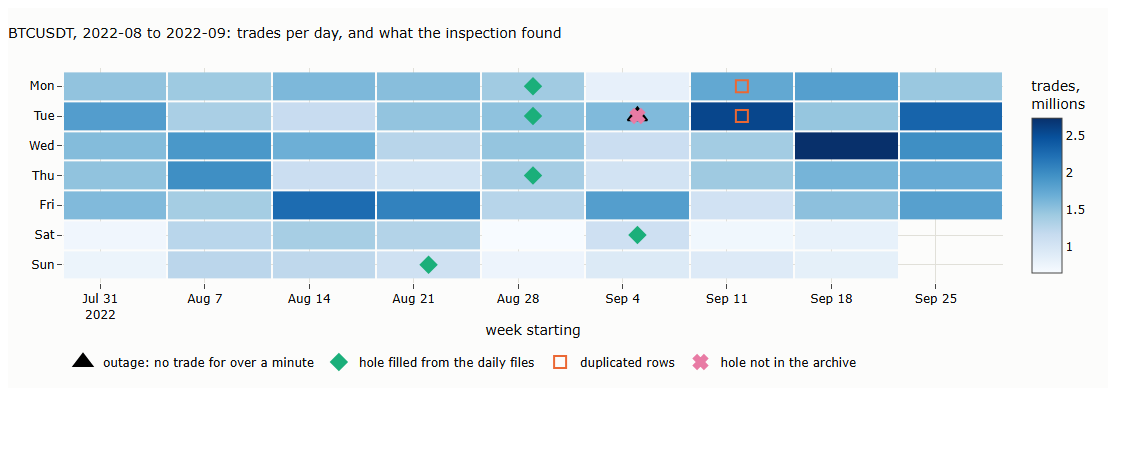

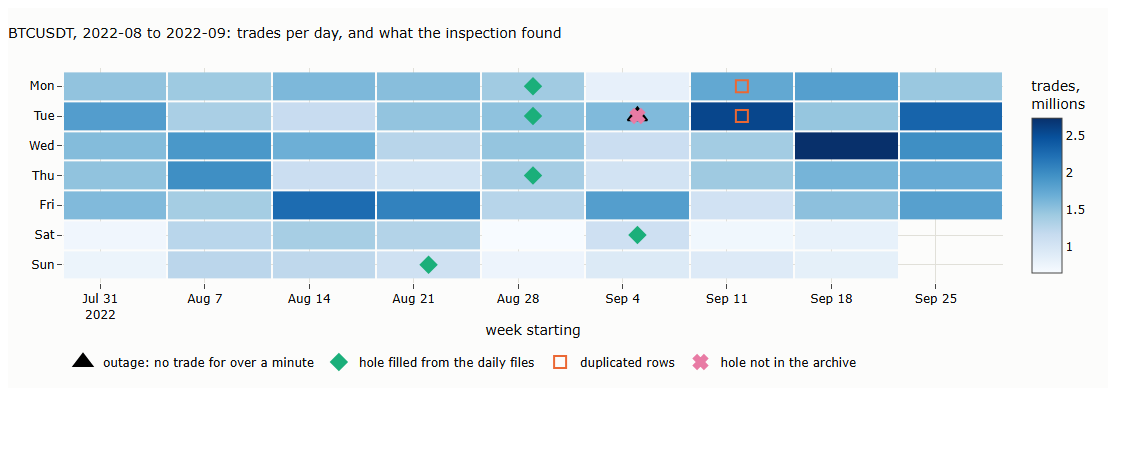

In [9]:
days = pl.concat([pl.read_parquet(D / ym / "days.parquet") for ym in period]).sort("day")
flags = pl.concat([pl.read_parquet(D / ym / "flag_counts.parquet") for ym in period])
marks = {"hole filled from the daily files": set(), "hole not in the archive": set(), "duplicated rows": set(), "outage: no trade for over a minute": set()}
for h in (patches.iter_rows(named=True) if patches.height else []):
    filled = h["status"] == "filled"
    marks["hole filled from the daily files" if filled else "hole not in the archive"].update(tape.hole_days(h["from_ms"], h["to_ms"], 60_000 if filled else 1))
for h in holes.filter(pl.col("kind") == "repeated").iter_rows(named=True):
    marks["duplicated rows"].add(datetime.fromtimestamp(h["from_ms"] / 1000, timezone.utc).date())
marks["outage: no trade for over a minute"] = {datetime.fromisoformat(d).date() for d in flags.filter(pl.col("rule") == "silence over 60 seconds")["day"]}

cal = days.with_columns(pl.col("day").dt.truncate("1w").alias("week"), pl.col("day").dt.weekday().alias("wd"))
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig = go.Figure(go.Heatmap(x=cal["week"], y=[names[w - 1] for w in cal["wd"]], z=cal["trades"] / 1e6, text=[str(d) for d in cal["day"]],
                           colorscale="Blues", colorbar=dict(title="trades,<br>millions"), xgap=2, ygap=2,
                           hovertemplate="%{text}: %{z:.2f} million trades<extra></extra>"))
for label, sym, col in (("outage: no trade for over a minute", "triangle-up", "black"), ("hole filled from the daily files", "diamond", SERIES[2]),
                        ("duplicated rows", "square-open", SERIES[1]), ("hole not in the archive", "x", SERIES[3])):
    ds_ = marks[label]
    q = cal.filter(pl.col("day").is_in(sorted(ds_)))
    fig.add_scatter(x=q["week"], y=[names[w - 1] for w in q["wd"]], mode="markers", marker=dict(symbol=sym, size=17 if sym == "triangle-up" else 12, color=col, line=dict(width=2, color=col)), name=label)
fig.update_yaxes(categoryorder="array", categoryarray=names[::-1]); fig.update_xaxes(title_text="week starting")
fig.update_layout(title=f"{SYMBOL}, {START} to {END}: trades per day, and what the inspection found", height=380, width=1100,
                  legend=dict(orientation="h", y=-0.3, x=0))
show(fig, "12_nb_coverage")

### 2.2 What to look at

The events of the map as a list: holes with their status, duplicated days, outages, and the days with the most unusual prints (§5.3).

In [10]:
ev = []
for h in (patches.iter_rows(named=True) if patches.height else []):
    ev.append(dict(when=datetime.fromtimestamp(h["from_ms"] / 1000, timezone.utc).strftime("%Y-%m-%d %H:%M:%S"), what=f"missing trades: {h['status']}", size=f"{h['n']:,} trades"))
for h in holes.filter(pl.col("kind") == "repeated").iter_rows(named=True):
    ev.append(dict(when=datetime.fromtimestamp(h["from_ms"] / 1000, timezone.utc).strftime("%Y-%m-%d"), what="duplicated rows (kept once in the clean month)", size=f"{h['n']:,} rows"))
ex = pl.concat([pl.read_parquet(D / ym / "flag_examples.parquet") for ym in period if pl.read_parquet(D / ym / "flag_examples.parquet").height])
for r in ex.filter(pl.col("rule") == "silence over 60 seconds").iter_rows(named=True):
    ev.append(dict(when=datetime.fromtimestamp(r["ms"] / 1000, timezone.utc).strftime("%Y-%m-%d %H:%M:%S"), what="outage: first trade after a silence", size=f"{r['value']:.0f} seconds"))
for r in flags.filter(pl.col("rule").is_in(["spike and revert", "jump that persists"])).group_by("day").agg(pl.col("n").sum()).sort("n", descending=True).head(5).iter_rows(named=True):
    ev.append(dict(when=r["day"], what="unusual prints (reverting or persisting)", size=f"{r['n']} prints"))
pl.DataFrame(ev).sort("when")

when,what,size
str,str,str
"""2022-08-19""","""unusual prints (reverting or persisting)""","""22 prints"""
"""2022-08-26""","""unusual prints (reverting or persisting)""","""16 prints"""
"""2022-08-27 23:59:59""","""missing trades: filled""","""3,977,571 trades"""
"""2022-08-31 23:59:59""","""missing trades: filled""","""1,377,907 trades"""
"""2022-09-06""","""unusual prints (reverting or persisting)""","""28 prints"""
"""2022-09-06 17:14:36""","""missing trades: not in the archive""","""31,645 trades"""
"""2022-09-06 17:20:57""","""outage: first trade after a silence""","""381 seconds"""
"""2022-09-06 17:58:09""","""missing trades: not in the archive""","""11 trades"""
"""2022-09-09 23:59:59""","""missing trades: filled""","""1,078,468 trades"""


### 2.3 Day view

Every trade of `DAY` (or of `WINDOW` within it), coloured by the aggressor's side. Flagged prints are ringed, and holes are shaded.
A whole day holds one to nine million trades: the chart shows a thinned set chosen to keep the shape of the path,
and with `INTERACTIVE = True` it fetches the full detail of whatever range you zoom into.

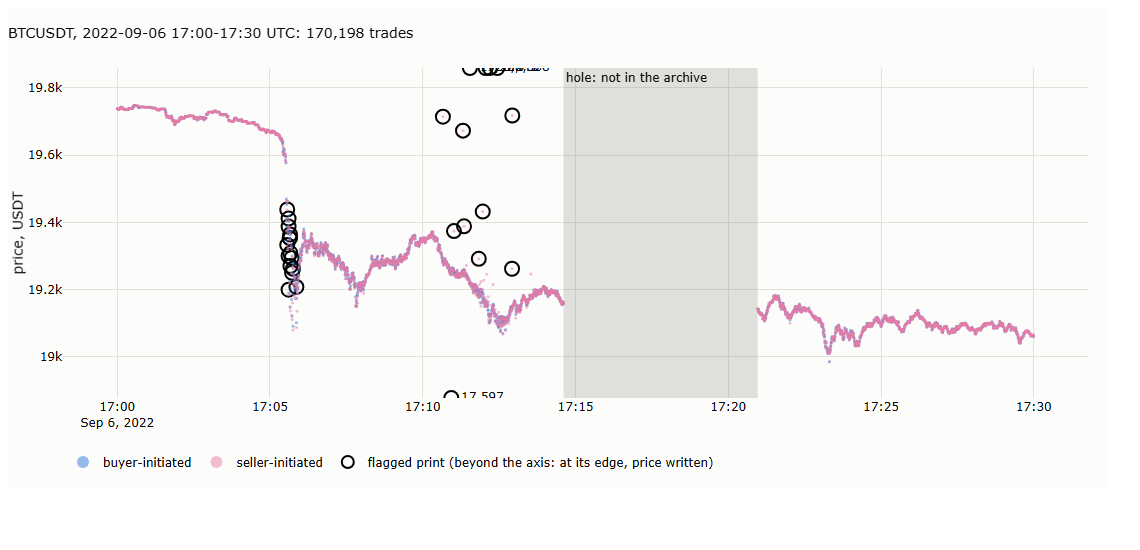

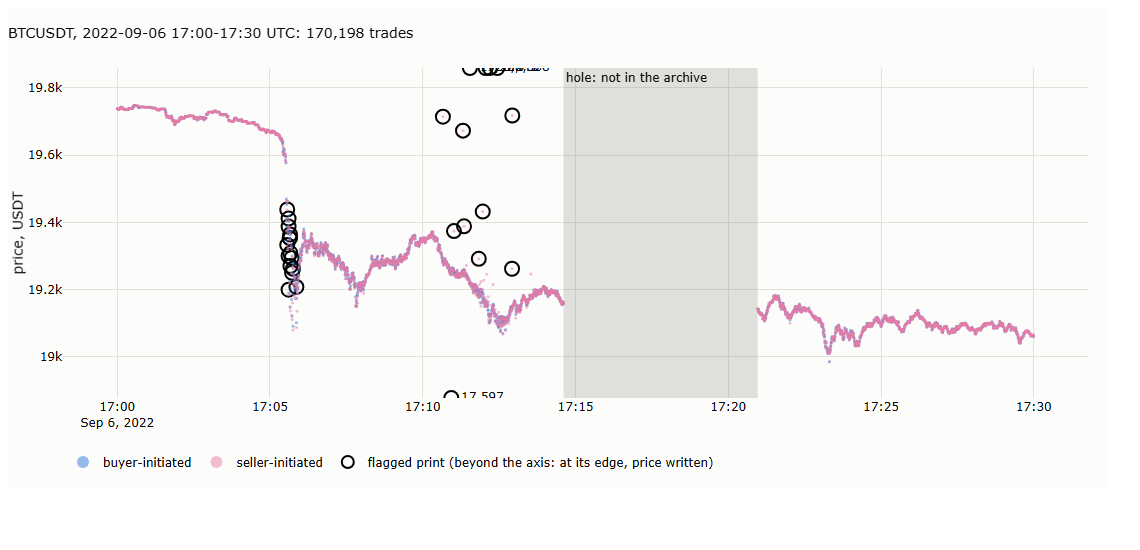

In [11]:
from plotly_resampler import FigureResampler

a, b = ms(f"{DAY} 00:00"), ms(f"{DAY} 00:00") + 86_400_000
if WINDOW:
    a, b = ms(f"{DAY} {WINDOW[0]}"), ms(f"{DAY} {WINDOW[1]}")
t = (pl.scan_parquet(tape.source(SYMBOL, DAY[:7])).filter(pl.col("transact_time").is_between(a, b, closed="left"))
       .select("transact_time", "price", "quantity", "is_buyer_maker").collect().with_columns(pl.from_epoch("transact_time", time_unit="ms").alias("time")))
fig = FigureResampler(go.Figure(), default_n_shown_samples=3000, show_mean_aggregation_size=False, resampled_trace_prefix_suffix=("", ""))
for maker, col, nm in ((False, SERIES[0], "buyer-initiated"), (True, SERIES[3], "seller-initiated")):
    q = t.filter(pl.col("is_buyer_maker") == maker)
    fig.add_trace(go.Scattergl(mode="markers", marker=dict(size=3, color=col, opacity=0.5), name=nm), hf_x=q["time"].to_numpy(), hf_y=q["price"].to_numpy())
# the price axis covers the bulk of the trades; flagged prints beyond it are drawn at its edge, with their price written next to them
y_lo, y_hi = (float(t["price"].quantile(0.0005)), float(t["price"].quantile(0.9995))) if t.height else (0.0, 1.0)
pad = (y_hi - y_lo) * 0.15 + 1e-9; y_lo, y_hi = y_lo - pad, y_hi + pad
f = ex.filter(pl.col("ms").is_between(a, b) & pl.col("rule").is_in(["spike and revert", "jump that persists"]))
fy = f["price"].clip(y_lo, y_hi); out_ = (f["price"] > y_hi) | (f["price"] < y_lo)
fig.add_trace(go.Scatter(x=pl.from_epoch(f["ms"], time_unit="ms"), y=fy, mode="markers+text", name="flagged print (beyond the axis: at its edge, price written)",
                         text=[f"{p:,.0f}" if o else "" for p, o in zip(f["price"], out_)], textposition="middle right",
                         marker=dict(size=14, symbol="circle-open", color="black", line=dict(width=2))))
for h in (patches.iter_rows(named=True) if patches.height else []):
    lo, hi = max(h["from_ms"], a), min(h["to_ms"], b)
    if lo < hi:
        fig.add_vrect(x0=datetime.fromtimestamp(lo / 1000, timezone.utc), x1=datetime.fromtimestamp(hi / 1000, timezone.utc), fillcolor=MUTED, opacity=0.25,
                      line_width=0, annotation_text=f"hole: {h['status']}", annotation_position="top left")
fig.update_yaxes(title_text="price, USDT", range=[y_lo, y_hi])
fig.update_layout(title=f"{SYMBOL}, {DAY} {'%s-%s UTC' % WINDOW if WINDOW else 'whole day'}: {t.height:,} trades", height=480, width=1100,
                  legend=dict(orientation="h", y=-0.15, x=0, itemsizing="constant"))
if INTERACTIVE:
    fig.show_dash(mode="inline")
else:
    show(fig, "12_nb_day")

### 2.4 Density

Millions of trades cannot be drawn as points. **Datashader** counts them into the pixels of an image instead: each pixel's shade is the dollars
traded at that time and price. The span is processed one day at a time and the day images are added, which is exact, because a sum can be
computed in chunks (Appendix A.1). The price axis spans the range of the one-minute closes, so isolated prints far outside it are not drawn.
The default, the afternoon and evening of the Fed decision of 21 September 2022, shows where the dollars traded as the price swung (§8.6).

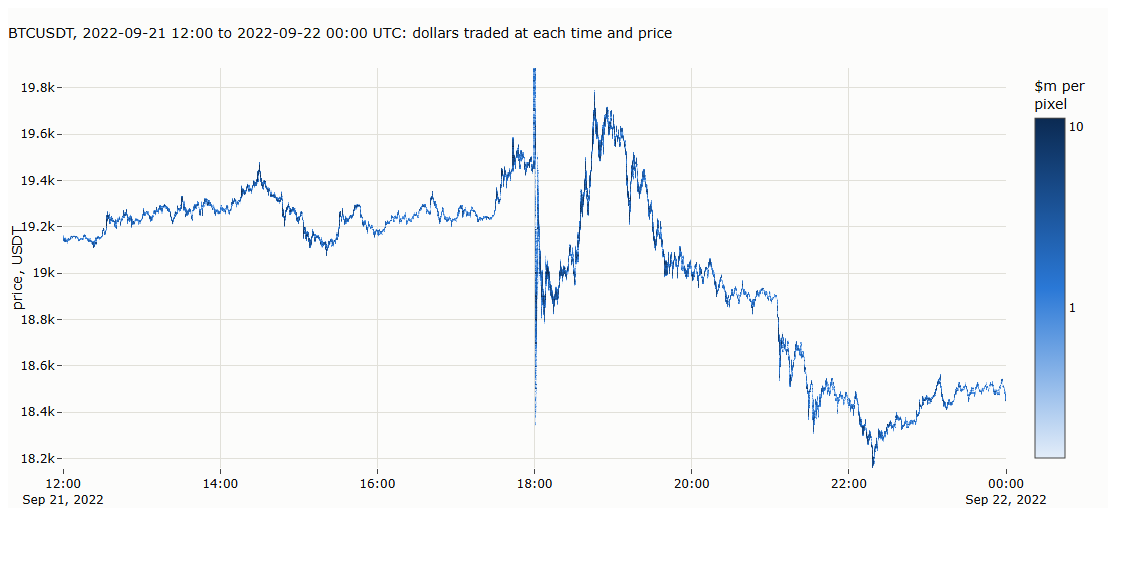

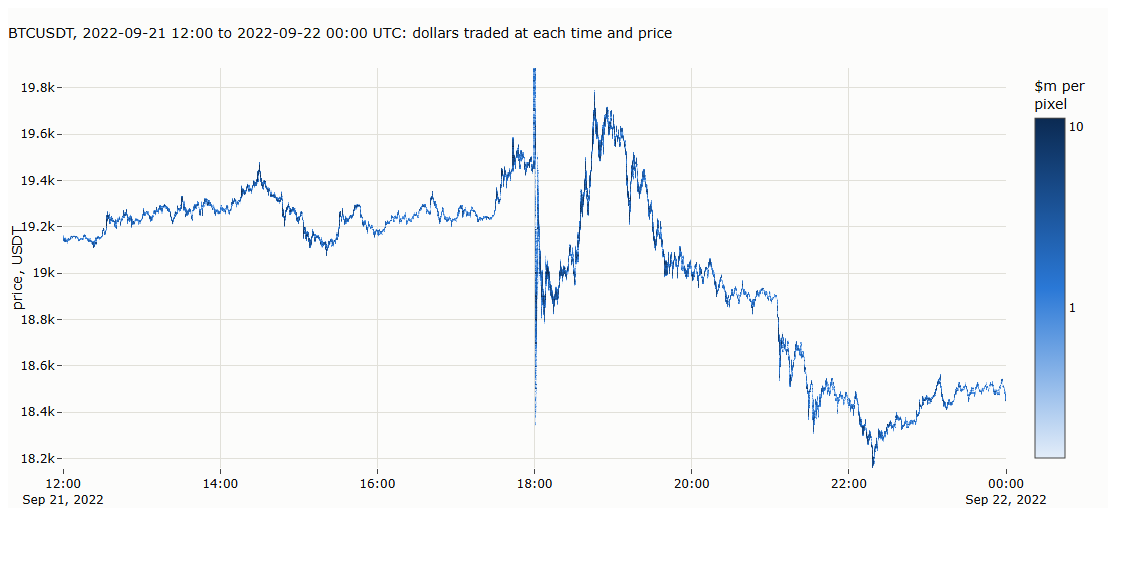

In [12]:
import datashader as ds

a, b = ms(DENSITY[0]), ms(DENSITY[1])
spans = sorted({datetime.fromtimestamp(x / 1000, timezone.utc).strftime("%Y-%m") for x in (a, b - 1)})
m1 = pl.concat([pl.read_parquet(D / ym / "m1.parquet", columns=["time", "close"]) for ym in spans]).filter(
    pl.col("time").is_between(datetime.fromtimestamp(a / 1000), datetime.fromtimestamp(b / 1000)))
lo, hi = float(m1["close"].min()) * 0.998, float(m1["close"].max()) * 1.002
canvas = ds.Canvas(plot_width=900, plot_height=360, x_range=(a, b), y_range=(lo, hi))
lf = pl.scan_parquet([tape.source(SYMBOL, ym) for ym in spans]).select("transact_time", "price", "quantity")
agg = None
for d0 in range(a, b, 86_400_000):                                     # one day at a time: bounded memory
    day = (lf.filter(pl.col("transact_time").is_between(d0, min(d0 + 86_400_000, b), closed="left"))
             .select(pl.col("transact_time").cast(pl.Float64), "price", (pl.col("price") * pl.col("quantity")).alias("usd")).collect().to_pandas())
    if len(day):
        part = canvas.points(day, "transact_time", "price", agg=ds.sum("usd"))
        part = part.fillna(0)                                          # empty pixels are NaN in Datashader: count them as zero dollars
        agg = part if agg is None else agg + part
z = np.log10(agg.values / 1e6, where=agg.values > 0, out=np.full(agg.shape, np.nan))   # millions of dollars per pixel, on a log scale
x = [datetime.fromtimestamp(v / 1000, timezone.utc).replace(tzinfo=None) for v in agg.coords["transact_time"].values]
fig = go.Figure(go.Heatmap(x=x, y=agg.coords["price"].values.tolist(), z=[[None if np.isnan(v) else round(float(v), 3) for v in row] for row in z],   # plain lists: portable HTML
                            colorscale=[[0, "#e3edf9"], [0.5, "#2a78d6"], [1, "#0b2a52"]], zmin=float(np.nanquantile(z, 0.05)), zmax=float(np.nanquantile(z, 0.995)),   # contrast: the bulk of the pixels
                           colorbar=dict(title="$m per<br>pixel", tickvals=[-2, -1, 0, 1, 2], ticktext=["0.01", "0.1", "1", "10", "100"]),
                           hovertemplate="%{x}<br>%{y:,.0f} USDT<extra></extra>"))
fig.update_yaxes(title_text="price, USDT")
fig.update_layout(title=f"{SYMBOL}, {DENSITY[0]} to {DENSITY[1]} UTC: dollars traded at each time and price", height=500, width=1100)
show(fig, "12_nb_density")

### 2.5 Raw rows

The rows of the tape around `ROWS_AT`: the trade's ID, its time, price, size and side, how many single fills it combines, and the gap in IDs
and in time to the row before. A jump in `id_gap` is a missing trade; a jump in `ms_gap` is a silence.

In [13]:
def rows_around(when, n=8):
    t0 = ms(when)
    w = (pl.scan_parquet(tape.source(SYMBOL, when[:7])).filter(pl.col("transact_time").is_between(t0 - 600_000, t0 + 600_000)).collect().sort("agg_trade_id")
           .with_columns(pl.from_epoch("transact_time", time_unit="ms").alias("time"), (pl.col("price") * pl.col("quantity")).round(0).alias("usd"),
                         pl.when(pl.col("is_buyer_maker")).then(pl.lit("sell")).otherwise(pl.lit("buy")).alias("aggressor"),
                         (pl.col("last_trade_id") - pl.col("first_trade_id") + 1).alias("fills"),
                         pl.col("agg_trade_id").diff().alias("id_gap"), pl.col("transact_time").diff().alias("ms_gap")))
    i = int(np.argmin(np.abs(w["transact_time"].to_numpy() - t0)))
    return w.slice(max(i - n, 0), 2 * n + 1).select("agg_trade_id", "time", "price", "quantity", "usd", "aggressor", "fills", "id_gap", "ms_gap")

rows_around(ROWS_AT)

agg_trade_id,time,price,quantity,usd,aggressor,fills,id_gap,ms_gap
i64,datetime[μs],f64,f64,f64,str,i64,i64,i64
1439638952,2022-09-06 17:12:26.328,19113.5,0.051,975.0,"""buy""",1,1,1
1439638953,2022-09-06 17:12:26.328,19112.5,0.204,3899.0,"""sell""",3,1,0
1439638954,2022-09-06 17:12:26.338,19113.5,0.281,5371.0,"""buy""",3,1,10
1439638955,2022-09-06 17:12:26.341,19112.4,0.049,937.0,"""sell""",4,1,3
1439638956,2022-09-06 17:12:26.358,19113.3,0.001,19.0,"""buy""",1,1,17
1439638957,2022-09-06 17:12:26.358,19113.5,0.049,937.0,"""buy""",1,1,0
1439638958,2022-09-06 17:12:26.359,19112.4,0.574,10971.0,"""sell""",3,1,1
1439638959,2022-09-06 17:12:26.370,19112.8,0.794,15176.0,"""buy""",4,1,11
1439638960,2022-09-06 17:12:26.397,19112.4,0.173,3306.0,"""sell""",3,1,27
